In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
SRC_DIR = PROJECT_ROOT / "src"

sys.path.append(str(SRC_DIR))

from load_data import load_data

In [2]:
X_train, X_test, y_train, y_test = load_data()

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

X_train: (1552, 26)
y_train: (1552,)
X_test : (389, 26)
y_test : (389,)


In [3]:
numeric_cols = get_numeric_cols(X_train)

print("수치형 변수 수:", len(numeric_cols))
print("범주형 변수:", CATEGORICAL_COLS)
print("전체 변수 수:", len(numeric_cols) + len(CATEGORICAL_COLS))

print("\n[결측치 상위]")
print(X_train.isna().sum().sort_values(ascending=False).head())

NameError: name 'get_numeric_cols' is not defined

In [ ]:
print("Train 전체 결측치:", X_train.isna().sum().sum())
print("Test 전체 결측치:", X_test.isna().sum().sum())

Train 전체 결측치: 0
Test 전체 결측치: 0


In [ ]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv

StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

baseline_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

baseline_lr;

In [ ]:
from sklearn.model_selection import cross_val_score

macro_f1_scores = cross_val_score(
    baseline_lr,
    X_train,
    y_train,
    cv=CV,
    scoring="f1_macro"
)

print("Fold별 Macro F1:", macro_f1_scores)
print("평균 Macro F1:", macro_f1_scores.mean())
print("표준편차:", macro_f1_scores.std())

Fold별 Macro F1: [0.75672918 0.69473085 0.72303664 0.69577958 0.73574939]
평균 Macro F1: 0.7212051280430262
표준편차: 0.02376633772025172


In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report

y_pred_cv = cross_val_predict(
    baseline_lr,
    X_train,
    y_train,
    cv=cv
)

print(classification_report(
    y_train,
    y_pred_cv,
    digits=3
))

              precision    recall  f1-score   support

       Bumps      0.624     0.558     0.589       321
   Dirtiness      0.649     0.545     0.593        44
   K_Scratch      0.930     0.930     0.930       313
Other_Faults      0.635     0.678     0.656       538
      Pastry      0.570     0.516     0.542       126
      Stains      0.917     0.948     0.932        58
   Z_Scratch      0.789     0.862     0.824       152

    accuracy                          0.715      1552
   macro avg      0.730     0.720     0.724      1552
weighted avg      0.713     0.715     0.713      1552



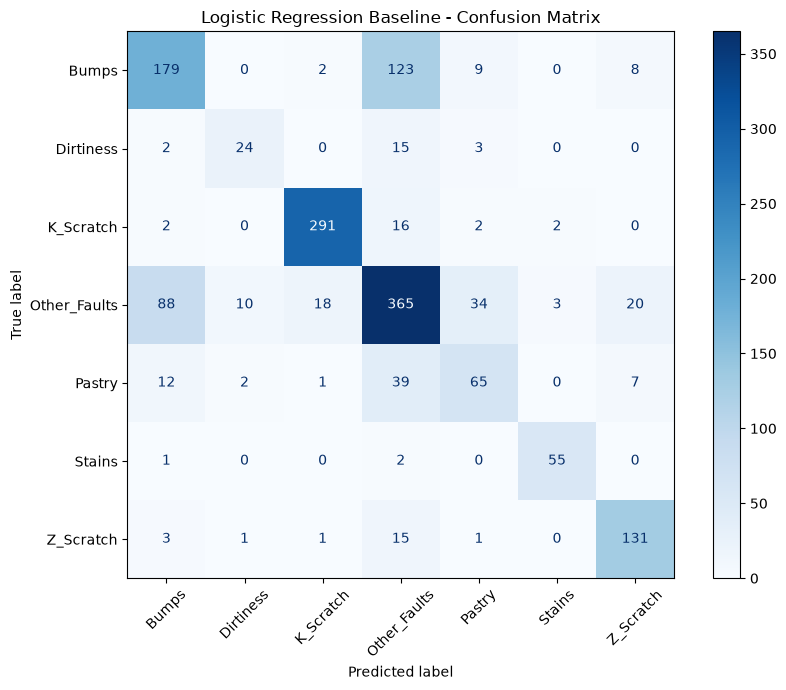

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(9, 7))

ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_pred_cv,
    cmap="Blues",
    xticks_rotation=45,
    ax=ax
)

ax.set_title("Logistic Regression Baseline - Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

lr_balanced = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

In [ ]:
from sklearn.model_selection import cross_val_score

balanced_f1_scores = cross_val_score(
    lr_balanced,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro"
)

print("Fold별 Macro F1:", balanced_f1_scores)
print("평균 Macro F1:", balanced_f1_scores.mean())
print("표준편차:", balanced_f1_scores.std())

Fold별 Macro F1: [0.67173548 0.66776185 0.66005162 0.67423516 0.67926631]
평균 Macro F1: 0.6706100836489268
표준편차: 0.006464233269593237


In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report

y_pred_balanced = cross_val_predict(
    lr_balanced,
    X_train,
    y_train,
    cv=cv
)

print(classification_report(
    y_train,
    y_pred_balanced,
    digits=3
))

              precision    recall  f1-score   support

       Bumps      0.614     0.645     0.629       321
   Dirtiness      0.319     0.818     0.459        44
   K_Scratch      0.902     0.946     0.924       313
Other_Faults      0.755     0.401     0.524       538
      Pastry      0.447     0.730     0.554       126
      Stains      0.800     0.966     0.875        58
   Z_Scratch      0.627     0.875     0.731       152

    accuracy                          0.668      1552
   macro avg      0.638     0.769     0.671      1552
weighted avg      0.707     0.668     0.660      1552



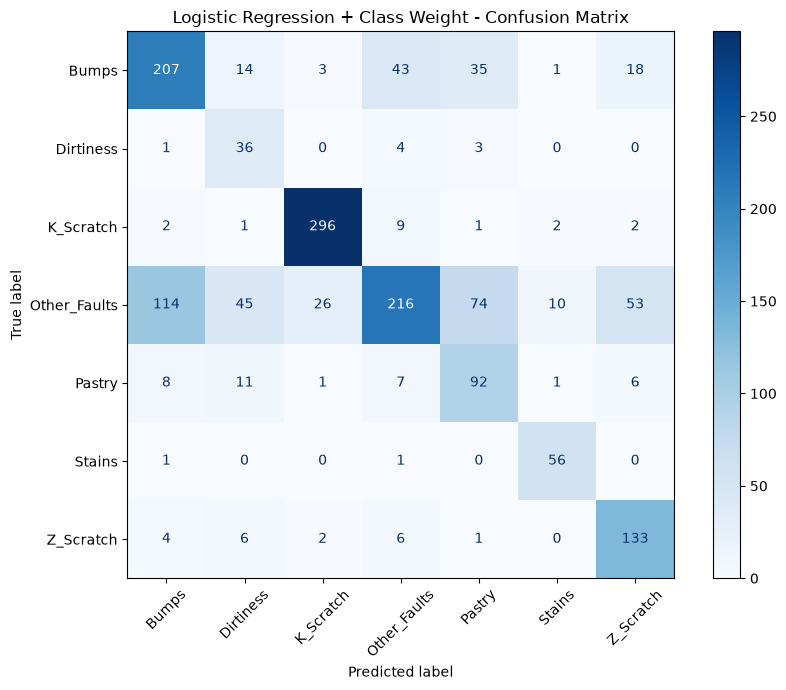

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(9, 7))

ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_pred_balanced,
    cmap="Blues",
    xticks_rotation=45,
    ax=ax
)

ax.set_title("Logistic Regression + Class Weight - Confusion Matrix")
plt.tight_layout()
plt.show()

class_weight='balanced' 적용 후 Bumps, Dirtiness, Pastry 등에서 Recall이 개선되었으며, 특히 Dirtiness의 Recall은 0.545에서 0.818, Pastry는 0.516에서 0.730으로 증가하였다. 반면 소수 클래스에 대한 예측이 적극적으로 이루어지면서 Precision이 감소했고, 특히 실제 Other_Faults가 다른 클래스들로 다수 오분류되어 Other_Faults Recall이 0.678에서 0.401로 크게 하락하였다.
결과적으로 Macro F1은 0.721에서 0.671로 감소하였다. 따라서 클래스 가중치는 일부 클래스의 미탐을 줄이는 효과가 있었으나, 그 과정에서 발생한 오탐 및 다수 클래스의 성능 저하가 커 현재 평가 기준에서는 Baseline보다 우수한 방법으로 판단하지 않았다.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score

baseline_dt = DecisionTreeClassifier(
    random_state=42
)

dt_f1_scores = cross_val_score(
    baseline_dt,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro"
)

print("Fold별 Macro F1:", dt_f1_scores)
print("평균 Macro F1:", dt_f1_scores.mean())
print("표준편차:", dt_f1_scores.std())

Fold별 Macro F1: [0.74776109 0.69661754 0.73084446 0.67575426 0.74722709]
평균 Macro F1: 0.7196408889451291
표준편차: 0.028751954787267994


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

baseline_rf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

rf_f1_scores = cross_val_score(
    baseline_rf,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

print("Fold별 Macro F1:", rf_f1_scores)
print("평균 Macro F1:", rf_f1_scores.mean())
print("표준편차:", rf_f1_scores.std())

Fold별 Macro F1: [0.77791096 0.7703867  0.81358148 0.73896896 0.79235765]
평균 Macro F1: 0.7786411505921089
표준편차: 0.024704332778770873


In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_score

baseline_gb = GradientBoostingClassifier(
    random_state=42
)

gb_f1_scores = cross_val_score(
    baseline_gb,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro"
)

print("Fold별 Macro F1:", gb_f1_scores)
print("평균 Macro F1:", gb_f1_scores.mean())
print("표준편차:", gb_f1_scores.std())

KeyboardInterrupt: 

In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report

# Random Forest OOF 예측
y_pred_rf = cross_val_predict(
    baseline_rf,
    X_train,
    y_train,
    cv=cv,
    n_jobs=-1
)

print("===== Random Forest Baseline =====")
print(classification_report(
    y_train,
    y_pred_rf,
    digits=3
))


# Gradient Boosting OOF 예측
y_pred_gb = cross_val_predict(
    baseline_gb,
    X_train,
    y_train,
    cv=cv
)

print("\n===== Gradient Boosting Baseline =====")
print(classification_report(
    y_train,
    y_pred_gb,
    digits=3
))

===== Random Forest Baseline =====
              precision    recall  f1-score   support

       Bumps      0.656     0.660     0.658       321
   Dirtiness      0.872     0.773     0.819        44
   K_Scratch      0.977     0.952     0.964       313
Other_Faults      0.669     0.757     0.710       538
      Pastry      0.671     0.437     0.529       126
      Stains      0.929     0.897     0.912        58
   Z_Scratch      0.914     0.836     0.873       152

    accuracy                          0.764      1552
   macro avg      0.813     0.759     0.781      1552
weighted avg      0.768     0.764     0.763      1552


===== Gradient Boosting Baseline =====
              precision    recall  f1-score   support

       Bumps      0.654     0.660     0.657       321
   Dirtiness      0.850     0.773     0.810        44
   K_Scratch      0.968     0.955     0.961       313
Other_Faults      0.710     0.757     0.733       538
      Pastry      0.619     0.516     0.563       126
   

동일한 5-fold Stratified CV에서 불균형 처리를 적용하지 않은 Baseline 모델을 비교한 결과, Logistic Regression 0.721, Decision Tree 0.720, Random Forest 0.779, Gradient Boosting 0.794의 평균 Macro F1을 기록하였다. Gradient Boosting은 가장 높은 평균 Macro F1과 가장 낮은 Fold 간 표준편차(0.015)를 보여 현재 Baseline 중 가장 우수하고 안정적인 성능을 보였다.
클래스별 성능에서는 모델 변경에 따라 Dirtiness, Other_Faults, Z_Scratch 등의 성능이 크게 개선되었으나, Pastry는 Gradient Boosting에서도 F1 0.563으로 상대적으로 낮았다. 따라서 클래스 불균형만으로 성능 차이를 설명하기보다는 클래스별 Feature 구분 난이도도 함께 고려할 필요가 있다.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

rf_balanced = RandomForestClassifier(
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_balanced_scores = cross_val_score(
    rf_balanced,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

print("Fold별 Macro F1:", rf_balanced_scores)
print("평균 Macro F1:", rf_balanced_scores.mean())
print("표준편차:", rf_balanced_scores.std())

Fold별 Macro F1: [0.80159928 0.79498022 0.767831   0.7658122  0.81361692]
평균 Macro F1: 0.7887679254331692
표준편차: 0.018899888320754323


In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report

y_pred_rf_balanced = cross_val_predict(
    rf_balanced,
    X_train,
    y_train,
    cv=cv,
    n_jobs=-1
)

print(classification_report(
    y_train,
    y_pred_rf_balanced,
    digits=3
))

              precision    recall  f1-score   support

       Bumps      0.618     0.766     0.684       321
   Dirtiness      0.804     0.841     0.822        44
   K_Scratch      0.974     0.949     0.961       313
Other_Faults      0.777     0.595     0.674       538
      Pastry      0.538     0.738     0.622       126
      Stains      0.857     0.931     0.893        58
   Z_Scratch      0.865     0.882     0.873       152

    accuracy                          0.761      1552
   macro avg      0.776     0.815     0.790      1552
weighted avg      0.777     0.761     0.762      1552



In [ ]:
import numpy as np

from sklearn.base import clone
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import f1_score

gb_weighted_scores = []

for train_idx, val_idx in cv.split(X_train, y_train):

    # Fold별 Train / Validation 분리
    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    # 해당 Training Fold에서만 balanced weight 계산
    sample_weights = compute_sample_weight(
        class_weight="balanced",
        y=y_fold_train
    )

    # 매 Fold마다 새로운 GB 모델
    model = clone(baseline_gb)

    # Training Fold에만 sample weight 적용
    model.fit(
        X_fold_train,
        y_fold_train,
        sample_weight=sample_weights
    )

    # Validation Fold 예측
    y_pred = model.predict(X_fold_val)

    # Macro F1
    score = f1_score(
        y_fold_val,
        y_pred,
        average="macro"
    )

    gb_weighted_scores.append(score)


gb_weighted_scores = np.array(gb_weighted_scores)

print("Fold별 Macro F1:", gb_weighted_scores)
print("평균 Macro F1:", gb_weighted_scores.mean())
print("표준편차:", gb_weighted_scores.std())

Fold별 Macro F1: [0.81805297 0.79426782 0.81325086 0.80890899 0.81176286]
평균 Macro F1: 0.8092487021072168
표준편차: 0.008054756243288148


In [ ]:
import numpy as np

from sklearn.base import clone
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import classification_report

y_pred_gb_weighted = np.empty(len(y_train), dtype=object)

for train_idx, val_idx in cv.split(X_train, y_train):

    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train.iloc[train_idx]

    sample_weights = compute_sample_weight(
        class_weight="balanced",
        y=y_fold_train
    )

    model = clone(baseline_gb)

    model.fit(
        X_fold_train,
        y_fold_train,
        sample_weight=sample_weights
    )

    y_pred_gb_weighted[val_idx] = model.predict(X_fold_val)


print(classification_report(
    y_train,
    y_pred_gb_weighted,
    digits=3
))

              precision    recall  f1-score   support

       Bumps      0.637     0.738     0.684       321
   Dirtiness      0.837     0.818     0.828        44
   K_Scratch      0.971     0.952     0.961       313
Other_Faults      0.774     0.673     0.720       538
      Pastry      0.597     0.683     0.637       126
      Stains      0.915     0.931     0.923        58
   Z_Scratch      0.899     0.941     0.920       152

    accuracy                          0.784      1552
   macro avg      0.804     0.819     0.810      1552
weighted avg      0.790     0.784     0.785      1552



In [ ]:
import xgboost

print(xgboost.__version__)

3.4.1


In [ ]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_xgb = label_encoder.fit_transform(y_train)

print("클래스:", label_encoder.classes_)
print("변환된 y:", y_train_xgb[:10])

클래스: ['Bumps' 'Dirtiness' 'K_Scratch' 'Other_Faults' 'Pastry' 'Stains'
 'Z_Scratch']
변환된 y: [2 0 0 2 2 3 6 3 2 4]


In [ ]:
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score

baseline_xgb = XGBClassifier(
    objective="multi:softprob",
    num_class=7,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

xgb_f1_scores = cross_val_score(
    baseline_xgb,
    X_train,
    y_train_xgb,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

print("Fold별 Macro F1:", xgb_f1_scores)
print("평균 Macro F1:", xgb_f1_scores.mean())
print("표준편차:", xgb_f1_scores.std())

Fold별 Macro F1: [0.81111917 0.81532462 0.85202219 0.75661049 0.8196383 ]
평균 Macro F1: 0.8109429561884169
표준편차: 0.030771283042222996


In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report

y_pred_xgb_encoded = cross_val_predict(
    baseline_xgb,
    X_train,
    y_train_xgb,
    cv=cv,
    n_jobs=-1
)

# 숫자 클래스 → 원래 클래스명
y_pred_xgb = label_encoder.inverse_transform(y_pred_xgb_encoded)

print(classification_report(
    y_train,
    y_pred_xgb,
    digits=3
))

              precision    recall  f1-score   support

       Bumps      0.670     0.682     0.676       321
   Dirtiness      0.921     0.795     0.854        44
   K_Scratch      0.971     0.965     0.968       313
Other_Faults      0.733     0.771     0.752       538
      Pastry      0.627     0.508     0.561       126
      Stains      0.947     0.931     0.939        58
   Z_Scratch      0.954     0.947     0.950       152

    accuracy                          0.794      1552
   macro avg      0.832     0.800     0.814      1552
weighted avg      0.794     0.794     0.794      1552



In [ ]:
import numpy as np

from sklearn.base import clone
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import f1_score

xgb_weighted_scores = []

for train_idx, val_idx in cv.split(X_train, y_train_xgb):

    # Fold별 Train / Validation 분리
    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train_xgb[train_idx]
    y_fold_val = y_train_xgb[val_idx]

    # Training Fold에서만 클래스 가중치 계산
    sample_weights = compute_sample_weight(
        class_weight="balanced",
        y=y_fold_train
    )

    # 매 Fold마다 새로운 XGBoost 모델
    model = clone(baseline_xgb)

    # Training Fold에만 sample weight 적용
    model.fit(
        X_fold_train,
        y_fold_train,
        sample_weight=sample_weights
    )

    # Validation Fold 예측
    y_pred = model.predict(X_fold_val)

    # Macro F1
    score = f1_score(
        y_fold_val,
        y_pred,
        average="macro"
    )

    xgb_weighted_scores.append(score)


xgb_weighted_scores = np.array(xgb_weighted_scores)

print("Fold별 Macro F1:", xgb_weighted_scores)
print("평균 Macro F1:", xgb_weighted_scores.mean())
print("표준편차:", xgb_weighted_scores.std())

Fold별 Macro F1: [0.80770608 0.79088753 0.8173979  0.75640842 0.80637828]
평균 Macro F1: 0.7957556420778049
표준편차: 0.021428685206700177


In [ ]:
import numpy as np

from sklearn.base import clone
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import classification_report

# OOF 예측값 저장
y_pred_xgb_weighted = np.empty(len(y_train_xgb), dtype=int)

for train_idx, val_idx in cv.split(X_train, y_train_xgb):

    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train_xgb[train_idx]

    # Training Fold에서만 가중치 계산
    sample_weights = compute_sample_weight(
        class_weight="balanced",
        y=y_fold_train
    )

    model = clone(baseline_xgb)

    model.fit(
        X_fold_train,
        y_fold_train,
        sample_weight=sample_weights
    )

    # Validation Fold 예측 저장
    y_pred_xgb_weighted[val_idx] = model.predict(X_fold_val)


# 숫자 → 원래 클래스명으로 복원
y_pred_xgb_weighted_label = label_encoder.inverse_transform(
    y_pred_xgb_weighted
)

print(classification_report(
    y_train,
    y_pred_xgb_weighted_label,
    digits=3
))

              precision    recall  f1-score   support

       Bumps      0.650     0.695     0.672       321
   Dirtiness      0.745     0.795     0.769        44
   K_Scratch      0.971     0.962     0.966       313
Other_Faults      0.747     0.723     0.735       538
      Pastry      0.602     0.563     0.582       126
      Stains      0.915     0.931     0.923        58
   Z_Scratch      0.929     0.941     0.935       152

    accuracy                          0.784      1552
   macro avg      0.794     0.801     0.797      1552
weighted avg      0.784     0.784     0.784      1552



In [ ]:
import imblearn

print(imblearn.__version__)

0.14.2


In [ ]:
categorical_feature = "TypeOfSteel_A300"

categorical_idx = X_train.columns.get_loc(categorical_feature)

print("범주형 Feature:", categorical_feature)
print("컬럼 위치:", categorical_idx)
print("고유값:", X_train[categorical_feature].unique())

범주형 Feature: TypeOfSteel_A300
컬럼 위치: 11
고유값: [0 1]


In [ ]:
from collections import Counter

for fold, (train_idx, val_idx) in enumerate(cv.split(X_train, y_train), start=1):
    y_fold_train = y_train.iloc[train_idx]
    
    class_counts = Counter(y_fold_train)
    min_count = min(class_counts.values())

    print(f"Fold {fold}")
    print(class_counts)
    print("최소 클래스 표본 수:", min_count)
    print("-" * 50)

Fold 1
Counter({'Other_Faults': 430, 'Bumps': 257, 'K_Scratch': 250, 'Z_Scratch': 122, 'Pastry': 101, 'Stains': 46, 'Dirtiness': 35})
최소 클래스 표본 수: 35
--------------------------------------------------
Fold 2
Counter({'Other_Faults': 430, 'Bumps': 257, 'K_Scratch': 250, 'Z_Scratch': 122, 'Pastry': 101, 'Stains': 46, 'Dirtiness': 35})
최소 클래스 표본 수: 35
--------------------------------------------------
Fold 3
Counter({'Other_Faults': 431, 'Bumps': 257, 'K_Scratch': 250, 'Z_Scratch': 121, 'Pastry': 101, 'Stains': 47, 'Dirtiness': 35})
최소 클래스 표본 수: 35
--------------------------------------------------
Fold 4
Counter({'Other_Faults': 431, 'Bumps': 256, 'K_Scratch': 251, 'Z_Scratch': 121, 'Pastry': 101, 'Stains': 47, 'Dirtiness': 35})
최소 클래스 표본 수: 35
--------------------------------------------------
Fold 5
Counter({'Other_Faults': 430, 'Bumps': 257, 'K_Scratch': 251, 'Z_Scratch': 122, 'Pastry': 100, 'Stains': 46, 'Dirtiness': 36})
최소 클래스 표본 수: 36
----------------------------------------------

In [ ]:
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

rf_smotenc = Pipeline([
    ("smotenc", SMOTENC(
        categorical_features=[categorical_idx],
        k_neighbors=5,
        random_state=42
    )),
    ("model", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

rf_smotenc_scores = cross_val_score(
    rf_smotenc,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

print("Fold별 Macro F1:", rf_smotenc_scores)
print("평균 Macro F1:", rf_smotenc_scores.mean())
print("표준편차:", rf_smotenc_scores.std())

Fold별 Macro F1: [0.80553439 0.80319639 0.80884915 0.76934566 0.80698838]
평균 Macro F1: 0.7987827944550333
표준편차: 0.014834230379522514


In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report

y_pred_rf_smotenc = cross_val_predict(
    rf_smotenc,
    X_train,
    y_train,
    cv=cv,
    n_jobs=-1
)

print(classification_report(
    y_train,
    y_pred_rf_smotenc,
    digits=3
))

              precision    recall  f1-score   support

       Bumps      0.647     0.754     0.696       321
   Dirtiness      0.822     0.841     0.831        44
   K_Scratch      0.974     0.965     0.970       313
Other_Faults      0.761     0.645     0.698       538
      Pastry      0.539     0.659     0.593       126
      Stains      0.932     0.948     0.940        58
   Z_Scratch      0.864     0.875     0.869       152

    accuracy                          0.773      1552
   macro avg      0.791     0.812     0.800      1552
weighted avg      0.781     0.773     0.774      1552



In [ ]:
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_score

gb_smotenc = Pipeline([
    ("smotenc", SMOTENC(
        categorical_features=[categorical_idx],
        k_neighbors=5,
        random_state=42
    )),
    ("model", GradientBoostingClassifier(
        random_state=42
    ))
])

gb_smotenc_scores = cross_val_score(
    gb_smotenc,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

print("Fold별 Macro F1:", gb_smotenc_scores)
print("평균 Macro F1:", gb_smotenc_scores.mean())
print("표준편차:", gb_smotenc_scores.std())

Fold별 Macro F1: [0.80487292 0.80123953 0.81790813 0.78815898 0.83085039]
평균 Macro F1: 0.8086059902164718
표준편차: 0.014612487299347684


In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report

y_pred_gb_smotenc = cross_val_predict(
    gb_smotenc,
    X_train,
    y_train,
    cv=cv,
    n_jobs=-1
)

print(classification_report(
    y_train,
    y_pred_gb_smotenc,
    digits=3
))

              precision    recall  f1-score   support

       Bumps      0.644     0.688     0.666       321
   Dirtiness      0.745     0.864     0.800        44
   K_Scratch      0.965     0.965     0.965       313
Other_Faults      0.758     0.682     0.718       538
      Pastry      0.622     0.706     0.662       126
      Stains      0.932     0.948     0.940        58
   Z_Scratch      0.893     0.934     0.913       152

    accuracy                          0.782      1552
   macro avg      0.794     0.827     0.809      1552
weighted avg      0.785     0.782     0.782      1552



In [ ]:
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score

xgb_smotenc = Pipeline([
    ("smotenc", SMOTENC(
        categorical_features=[categorical_idx],
        k_neighbors=5,
        random_state=42
    )),
    ("model", XGBClassifier(
        objective="multi:softprob",
        num_class=7,
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_smotenc_scores = cross_val_score(
    xgb_smotenc,
    X_train,
    y_train_xgb,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

print("Fold별 Macro F1:", xgb_smotenc_scores)
print("평균 Macro F1:", xgb_smotenc_scores.mean())
print("표준편차:", xgb_smotenc_scores.std())

Fold별 Macro F1: [0.8232264  0.82256639 0.8239974  0.78140724 0.83358564]
평균 Macro F1: 0.8169566149111663
표준편차: 0.018224352256940198


In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report

y_pred_xgb_smotenc_encoded = cross_val_predict(
    xgb_smotenc,
    X_train,
    y_train_xgb,
    cv=cv,
    n_jobs=-1
)

# 숫자 클래스 → 원래 클래스명
y_pred_xgb_smotenc = label_encoder.inverse_transform(
    y_pred_xgb_smotenc_encoded
)

print(classification_report(
    y_train,
    y_pred_xgb_smotenc,
    digits=3
))

              precision    recall  f1-score   support

       Bumps      0.696     0.720     0.708       321
   Dirtiness      0.783     0.818     0.800        44
   K_Scratch      0.965     0.974     0.970       313
Other_Faults      0.766     0.730     0.748       538
      Pastry      0.620     0.635     0.627       126
      Stains      0.949     0.966     0.957        58
   Z_Scratch      0.904     0.934     0.919       152

    accuracy                          0.801      1552
   macro avg      0.812     0.825     0.818      1552
weighted avg      0.801     0.801     0.801      1552



In [ ]:
from sklearn.model_selection import RandomizedSearchCV

param_distributions = {
    "model__n_estimators": [100, 200, 300, 500],
    "model__max_depth": [2, 3, 4, 5, 6],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "model__min_child_weight": [1, 3, 5, 7]
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_smotenc,
    param_distributions=param_distributions,
    n_iter=30,
    scoring="f1_macro",
    cv=CV,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

xgb_search.fit(X_train, y_train_xgb);

Fitting 5 folds for each of 30 candidates, totalling 150 fits


c:\Users\yunha\KANT-study\steel-plate-fault-classification\.venv\Lib\site-packages\joblib\externals\loky\process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


In [ ]:
print("Best Parameters:")
print(xgb_search.best_params_)

print("\nBest CV Macro F1:")
print(xgb_search.best_score_)

Best Parameters:
{'model__n_estimators': 300, 'model__min_child_weight': 1, 'model__max_depth': 5, 'model__learning_rate': 0.05}

Best CV Macro F1:
0.8200871389180623


In [ ]:
best_idx = xgb_search.best_index_

best_train_score = xgb_search.cv_results_["mean_train_score"][best_idx]
best_val_score = xgb_search.cv_results_["mean_test_score"][best_idx]
best_val_std = xgb_search.cv_results_["std_test_score"][best_idx]

print("Train Macro F1:", best_train_score)
print("CV Macro F1:", best_val_score)
print("Train - CV Gap:", best_train_score - best_val_score)
print("CV 표준편차:", best_val_std)

Train Macro F1: 0.999645116298848
CV Macro F1: 0.8200871389180623
Train - CV Gap: 0.17955797738078572
CV 표준편차: 0.022462009298855362


In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__max_depth": [2, 3, 4],
    "model__min_child_weight": [3, 5, 7],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__n_estimators": [100, 200, 300]
}

xgb_grid = GridSearchCV(
    estimator=xgb_smotenc,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

xgb_grid.fit(X_train, y_train_xgb)

print("Best Parameters:")
print(xgb_grid.best_params_)

print("\nBest CV Macro F1:")
print(xgb_grid.best_score_)

Fitting 5 folds for each of 81 candidates, totalling 405 fits
Best Parameters:
{'model__learning_rate': 0.1, 'model__max_depth': 4, 'model__min_child_weight': 3, 'model__n_estimators': 100}

Best CV Macro F1:
0.8136225029558435


In [ ]:
best_idx = xgb_grid.best_index_

train_score = xgb_grid.cv_results_["mean_train_score"][best_idx]
cv_score = xgb_grid.cv_results_["mean_test_score"][best_idx]
cv_std = xgb_grid.cv_results_["std_test_score"][best_idx]

print("Train Macro F1:", train_score)
print("CV Macro F1:", cv_score)
print("Train - CV Gap:", train_score - cv_score)
print("CV 표준편차:", cv_std)

Train Macro F1: 0.9615610088678188
CV Macro F1: 0.8136225029558435
Train - CV Gap: 0.14793850591197533
CV 표준편차: 0.019121504900729953


In [ ]:
from sklearn.model_selection import cross_validate

xgb_smotenc_cv = cross_validate(
    xgb_smotenc,
    X_train,
    y_train_xgb,
    cv=cv,
    scoring="f1_macro",
    return_train_score=True,
    n_jobs=-1
)

train_mean = xgb_smotenc_cv["train_score"].mean()
cv_mean = xgb_smotenc_cv["test_score"].mean()
train_cv_gap = train_mean - cv_mean

print(f"Train Macro F1: {train_mean:.4f}")
print(f"CV Macro F1:    {cv_mean:.4f}")
print(f"Train-CV Gap:   {train_cv_gap:.4f}")
print(f"CV Std:         {xgb_smotenc_cv['test_score'].std():.4f}")

Train Macro F1: 1.0000
CV Macro F1:    0.8170
Train-CV Gap:   0.1830
CV Std:         0.0182
